In [1]:
import numpy as np
from numba import njit, prange
from scipy.stats import lognorm
import matplotlib.pyplot as plt

In [10]:
class LucasTree:
    """
    Classe para guardar os parâmetros do modelo da árvore de Lucas.
    """

    def __init__(self,
                 gamma = 2,             # Parâmetro de utilidade (função CRRA: constant relative risk aversion)
                 beta = 0.95,           # Fator de desconto intertemporal
                 alpha = 0.90,          # Coeficiente de correlação
                 sigma = 0.1,           # Coeficiente de volatilidade
                 grid_size = 100):

        self.gamma, self.beta, self.alpha, self.sigma = gamma, beta, alpha, sigma

        # Set the grid interval to contain most of the mass of the
        # stationary distribution of the consumption endowment
        ssd = self.sigma / np.sqrt(1 - self.alpha**2)
        grid_min, grid_max = np.exp(-4 * ssd), np.exp(4 * ssd)
        self.grid = np.linspace(grid_min, grid_max, grid_size)
        self.grid_size = grid_size

        # Distribuição dos choques
        self.phi = lognorm(sigma)
        self.draws = self.phi.rvs(500)

        self.h = np.empty(self.grid_size)
        for i,y in enumerate(self.grid):
            self.h[i] = beta * np.mean((y**alpha * self.draws) ** (1 - gamma))

In [11]:
def operator_factory(tree, parallel_flag=True):
    """
    Retorna o operador de Lucas aproximado, que computa e retorna a 
    função atualizada Tf nos pontos na grade.

    tree é uma instância da classe LucasTree
    """

    grid, h = tree.grid, tree.h
    alpha, beta = tree.alpha, tree.beta
    z_vec = tree.draws

    @njit(parallel=parallel_flag)
    def T(f):
        """
        Operador de Lucas
        """

        # Tornar f uma função
        Af = lambda x: np.interp(x, grid, f)
        Tf = np.empty_like(f)

        # Aplicar o operador T à f usando integração de Monte Carlo
        for i in prange(len(grid)):
            y = grid[i]
            Tf[i] = h[i] + beta * np.mean(Af(y**alpha * z_vec))

        return Tf

    return T

In [13]:
def solve_model(tree, tol=1e-6, max_iter=500):
    """
    Computa a função preço de equilíbrio associada à árvore de Lucas
    """

    grid, grid_size = tree.grid, tree.grid_size
    gamma = tree.gamma

    T = operator_factory(tree)

    i = 0
    f = np.ones_like(grid)
    error = tol + 1
    while error > tol and i < max_iter:
        Tf = T(f)
        error = np.max(np.abs(Tf - f))
        f = Tf
        i += 1

    price = f * grid**gamma

    return price

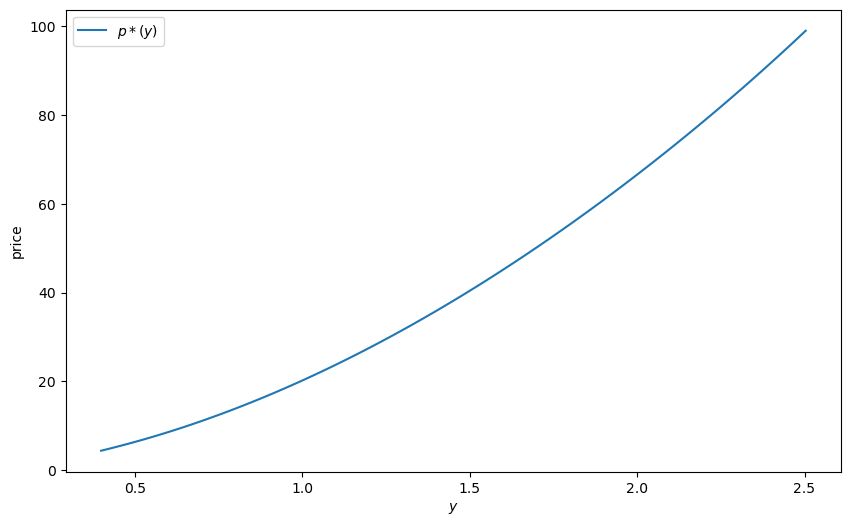

In [14]:
tree = LucasTree()
price_vals = solve_model(tree)

fig, ax = plt.subplots(figsize=(10,6))
ax.plot(tree.grid, price_vals, label = '$p*(y)$')
ax.set_xlabel('$y$')
ax.set_ylabel('price')
ax.legend()
plt.show()

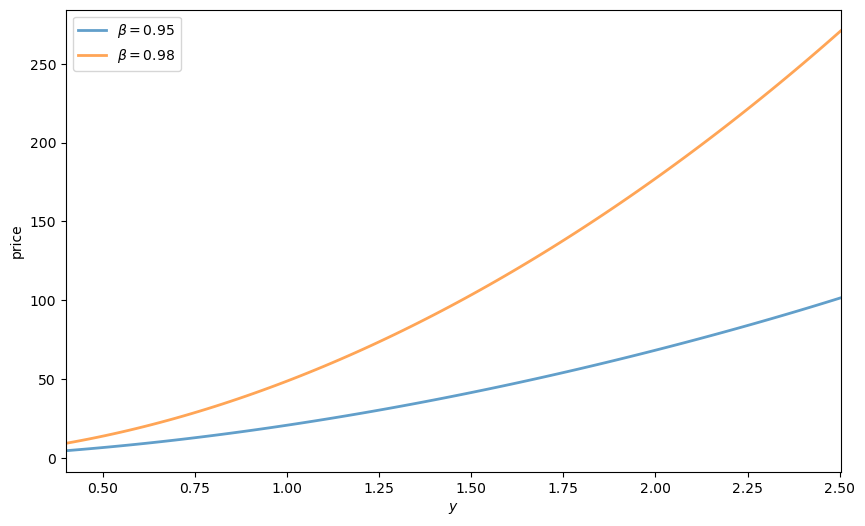

In [15]:
fig, ax = plt.subplots(figsize = (10,6))

for beta in (.95, .98):
    tree = LucasTree(beta = beta)
    grid = tree.grid
    price_vals = solve_model(tree)
    label = rf'$\beta = {beta}$'
    ax.plot(grid, price_vals, lw=2, alpha = 0.7, label=label)

ax.legend(loc = 'upper left')
ax.set(xlabel='$y$', ylabel='price', xlim=(min(grid), max(grid)))
plt.show()